# Reproduce the result figure

Run all cells with Python 3.11 or 3.12 to regenerate the paired ECE figure from `results/per_seed.csv`, which contains the 20 recorded experimental runs. The notebook uses the same plotting script as the command-line workflow.


In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "code/plot.py").is_file() and (p / "results/per_seed.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository directory.")

_ = subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet",
     "-r", str(ROOT / "requirements/analysis.txt")],
    check=True, capture_output=True, text=True,
)
print("Analysis environment ready.")


Analysis environment ready.


## Paired ECE measurements

The left panel compares global temperature scaling with group calibration. The right panel compares original and shuffled features. Each row pairs the same seed; the last row shows the means. Lower ECE is better.


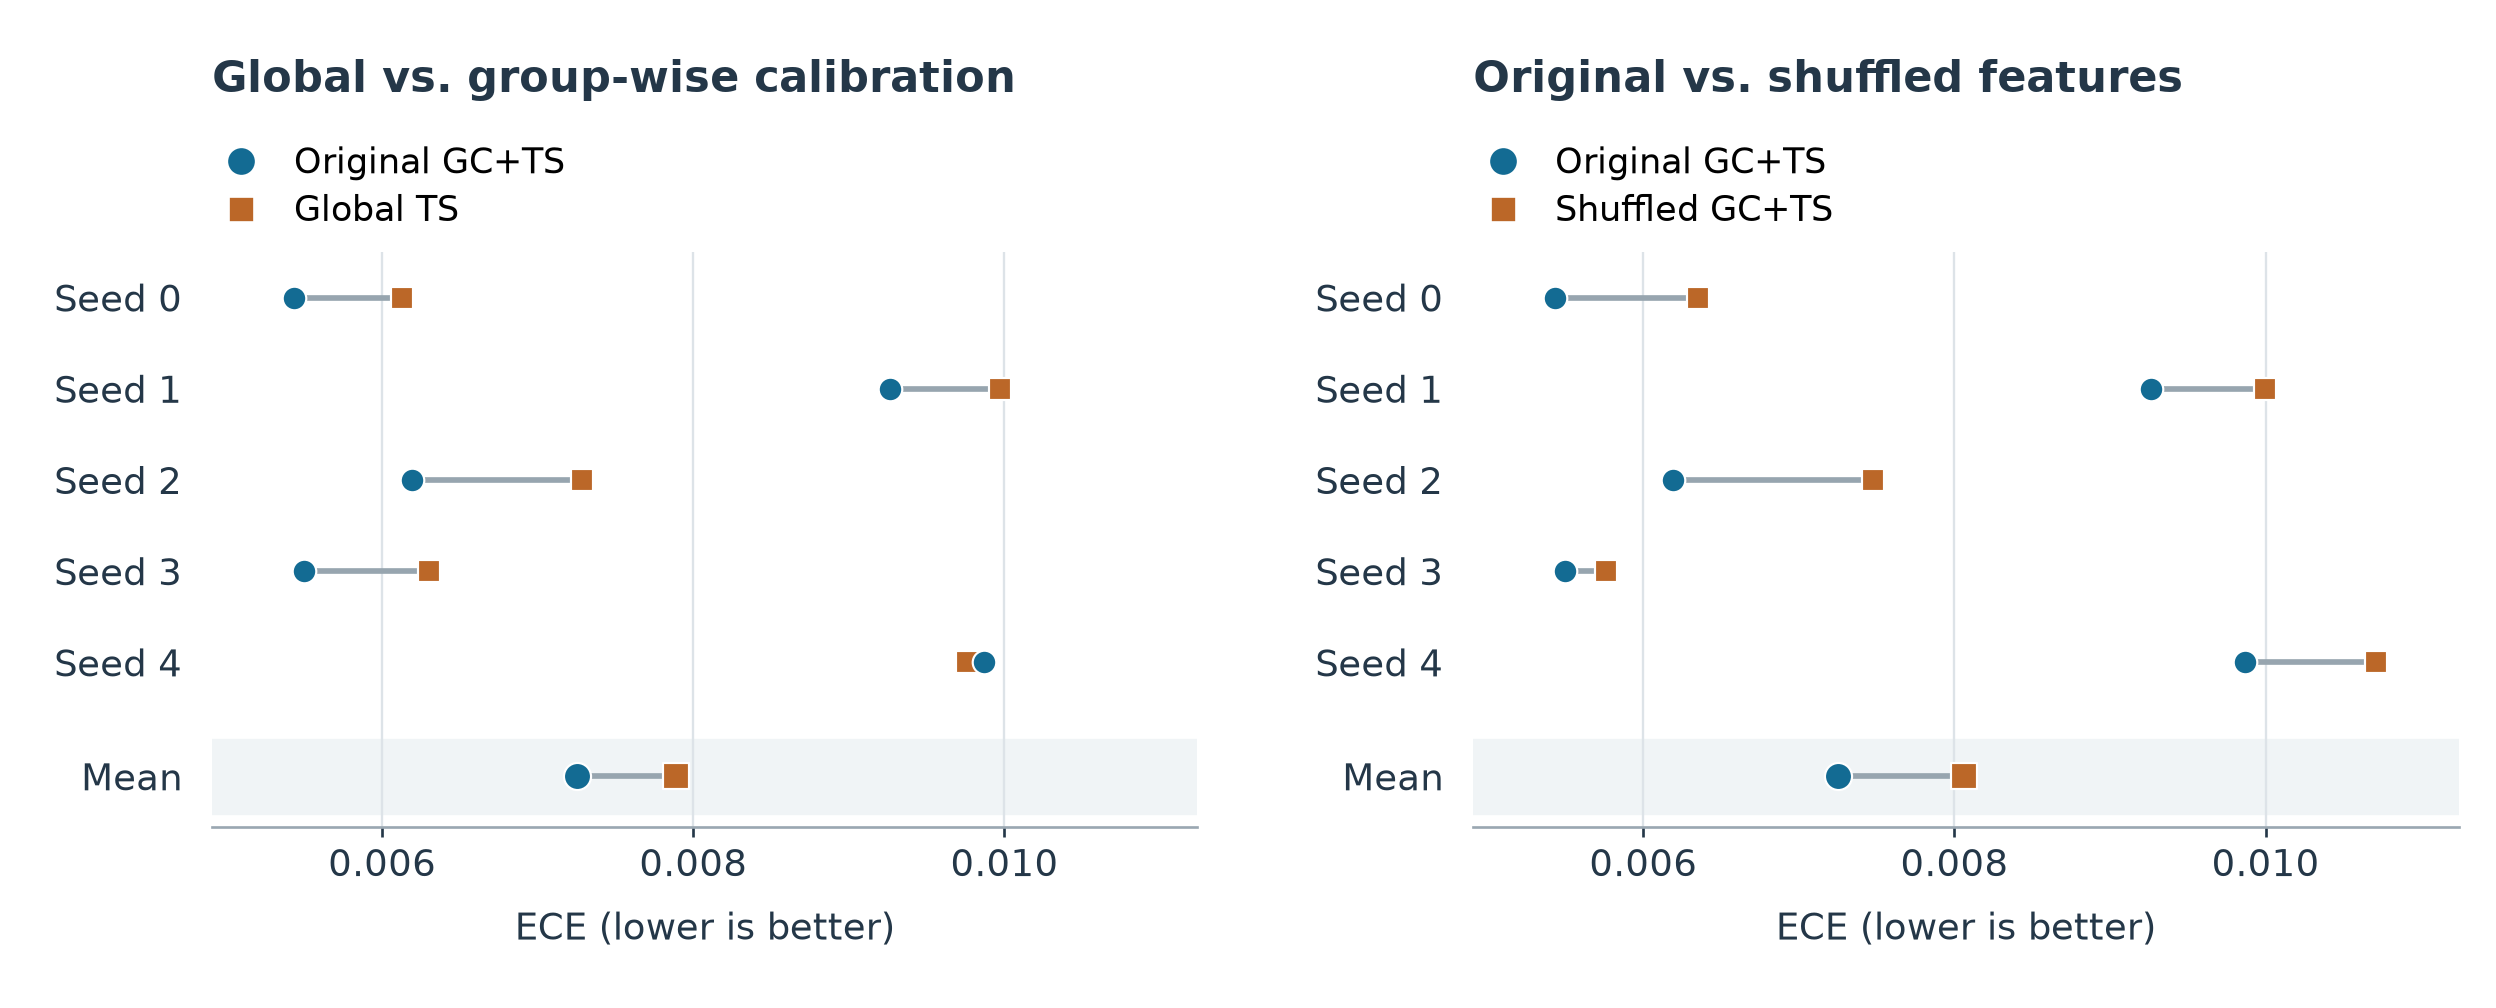

In [2]:
from IPython.display import Image, display

OUTPUT = ROOT / "outputs/notebook"
_ = subprocess.run(
    [sys.executable, str(ROOT / "code/plot.py"),
     "--input", str(ROOT / "results/per_seed.csv"),
     "--output", str(OUTPUT),
     "--formats", "png", "svg", "pdf"],
    check=True, capture_output=True, text=True,
)
display(Image(filename=str(OUTPUT / "paired_ece.png"), width=1040))


The figure is exported to `outputs/notebook/paired_ece.png`, `paired_ece.svg`, and `paired_ece.pdf`.
